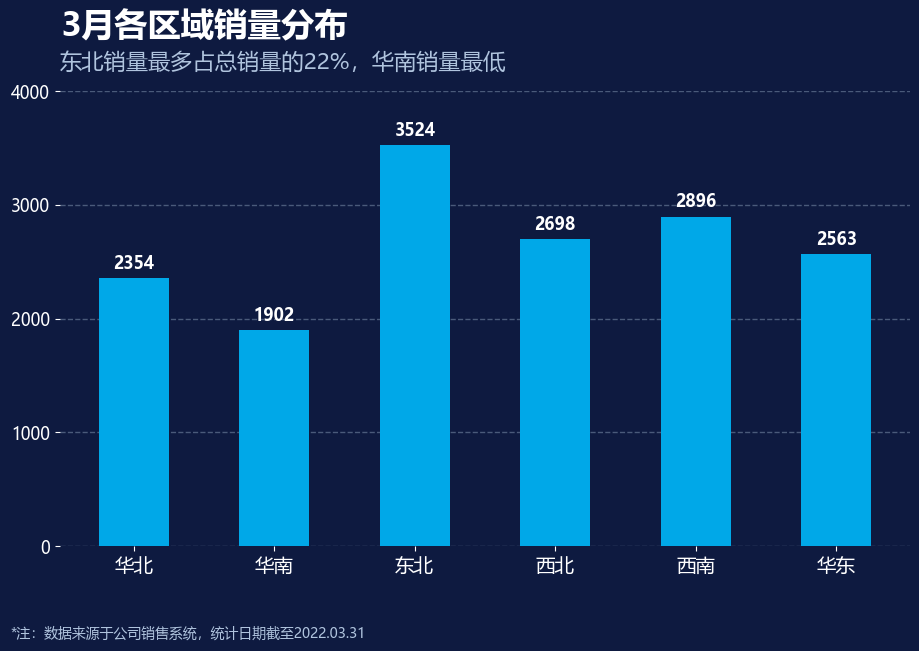

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# ========== 中文字体设置 ==========
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 公共数据 ==========
regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales = [2354, 1902, 3524, 2698, 2896, 2563]

# ============================================================
# 图1：渐变柱形图
# ============================================================
total = sum(sales)
max_region = regions[sales.index(max(sales))]
max_percent = max(sales) / total * 100
min_region = regions[sales.index(min(sales))]

fig1, ax1 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax1.set_facecolor('#0E1A40')

bar_color = '#00A8E8'
bars1 = ax1.bar(regions, sales, color=bar_color, width=0.5, zorder=3)

for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, height + 50, f'{height}',
             ha='center', va='bottom', color='white', fontsize=12, fontweight='bold')

ax1.set_title('3月各区域销量分布', color='white', fontsize=24, fontweight='bold', pad=40, loc='left')
ax1.text(0, 1.04, f'{max_region}销量最多占总销量的{max_percent:.0f}%，{min_region}销量最低',
         transform=ax1.transAxes, color='#B0C4DE', fontsize=16, ha='left', va='bottom')

ax1.set_ylim(0, 4000)
ax1.set_yticks([0, 1000, 2000, 3000, 4000])
ax1.tick_params(axis='y', colors='white', labelsize=12)
ax1.tick_params(axis='x', colors='white', labelsize=14)

ax1.yaxis.grid(True, color='#4A5A7A', linestyle='--', linewidth=1, zorder=0)

for spine in ax1.spines.values():
    spine.set_visible(False)

fig1.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.03.31',
          color='#B0C4DE', fontsize=10)

plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)
fig1.savefig('图1_渐变柱形图.png', dpi=300,
             facecolor=fig1.get_facecolor(), bbox_inches='tight')
plt.show()  # 显示图片
plt.close(fig1)

In [ ]:
# ============================================================
# 图2：带均值柱形图
# ============================================================
mean_value = np.mean(sales)  # 整体均值 2656.17

fig2, ax2 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax2.set_facecolor('#0E1A40')

bars2 = ax2.bar(regions, sales, color='#00A8E8', width=0.5, zorder=3)

for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, height + 50, f'{height}',
             ha='center', va='bottom', color='white', fontsize=12, fontweight='bold')

# 添加均值水平线
ax2.axhline(y=mean_value, color='#FFA500', linestyle='--', linewidth=2,
            zorder=4, label=f'均值：{mean_value:.2f}')

ax2.set_title('各区域销量与均值对比', color='white', fontsize=24,
              fontweight='bold', pad=40, loc='left')
ax2.text(0, 1.04, f'整体销量均值：{mean_value:.2f}',
         transform=ax2.transAxes, color='#B0C4DE', fontsize=16,
         ha='left', va='bottom')

ax2.set_ylim(0, 4000)
ax2.set_yticks([0, 1000, 2000, 3000, 4000])
ax2.tick_params(axis='y', colors='white', labelsize=12)
ax2.tick_params(axis='x', colors='white', labelsize=14)

ax2.yaxis.grid(True, color='#4A5A7A', linestyle='--', linewidth=1, zorder=0)

for spine in ax2.spines.values():
    spine.set_visible(False)

# 图例样式
legend = ax2.legend(loc='upper right', facecolor='#0E1A40',
                    edgecolor='none', fontsize=12)
for text in legend.get_texts():
    text.set_color('white')

fig2.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.03.31',
          color='#B0C4DE', fontsize=10)

plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)
fig2.savefig('图2_带均值柱形图.png', dpi=300,
             facecolor=fig2.get_facecolor(), bbox_inches='tight')
plt.show()  # 显示图片
plt.close(fig2)

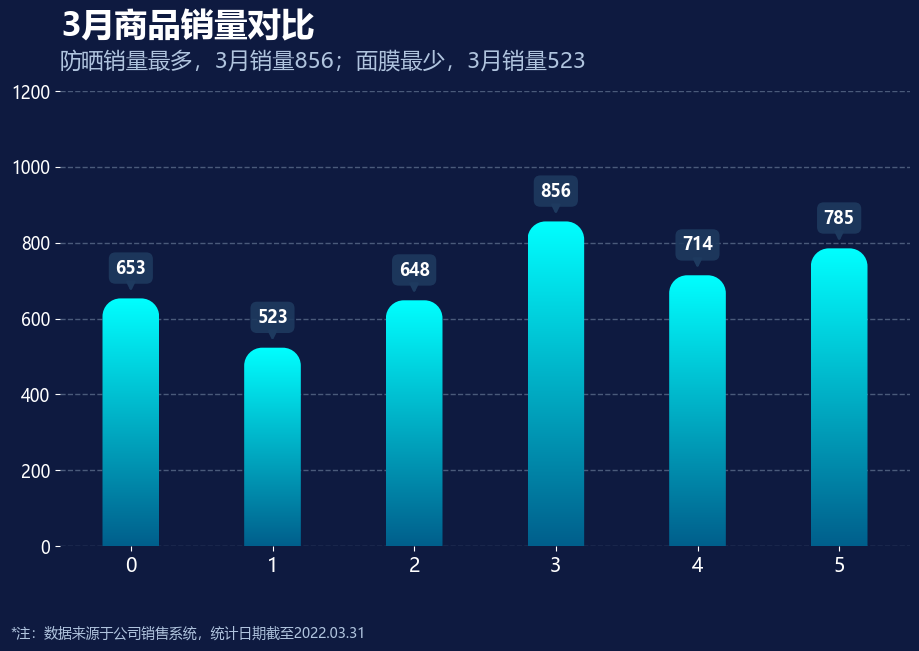

图3已保存至：图3_渐变圆角柱形图.png


In [5]:
import matplotlib.patches as patches
import matplotlib.colors as mcolors
from matplotlib.path import Path
from matplotlib.patches import PathPatch

# ============================================================
# 图3：渐变圆角柱形图（真正的圆角）
# ============================================================
items = ['口红', '面膜', '隔离', '防晒', '精华', '面霜']
sales_3 = [653, 523, 648, 856, 714, 785]

max_item = items[sales_3.index(max(sales_3))]
max_item_sales = max(sales_3)
min_item = items[sales_3.index(min(sales_3))]
min_item_sales = min(sales_3)

fig3, ax3 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax3.set_facecolor('#0E1A40')

# 固定坐标轴范围
ax3.set_xlim(-0.5, len(items) - 0.5)
ax3.set_ylim(0, 1200)

# 渐变色：底部深蓝 → 顶部亮青
cmap = mcolors.LinearSegmentedColormap.from_list("custom", ["#005F8C", "#00FFFF"])

# ---------- 计算像素比例，用于补偿 x/y 轴比例差异 ----------
fig_w_px = fig3.get_figwidth() * fig3.dpi
fig_h_px = fig3.get_figheight() * fig3.dpi
left, right, bottom, top = 0.1, 0.95, 0.15, 0.8   # 与 subplots_adjust 保持一致
axes_w_px = fig_w_px * (right - left)
axes_h_px = fig_h_px * (top - bottom)

x_range = ax3.get_xlim()[1] - ax3.get_xlim()[0]   # 6
y_range = ax3.get_ylim()[1] - ax3.get_ylim()[0]   # 1200
px_per_x = axes_w_px / x_range                    # 约 113 px / x单位
px_per_y = axes_h_px / y_range                    # 约 0.38 px / y单位

# ---------- 绘制每根柱子 ----------
bar_width = 0.4
r_visual_px = 18           # 视觉上的圆角半径（像素）
k = 0.5522847498           # 贝塞尔逼近圆弧的常数

for i, val in enumerate(sales_3):
    # 根据像素比例换算数据坐标下的圆角半径
    r_x = min(r_visual_px / px_per_x, bar_width / 2)   # x方向半径
    r_y = min(r_visual_px / px_per_y, val / 2)         # y方向半径（会很大）

    x0 = i - bar_width / 2
    x1 = i + bar_width / 2
    y0 = 0
    y1 = val

    # 柱子轮廓：底部直角，顶部两个圆角
    verts = [
        (x0, y0),                          # 左下
        (x0, y1 - r_y),                    # 左侧直边结束
        (x0, y1 - r_y + k * r_y),          # 左上圆角控制点1
        (x0 + r_x - k * r_x, y1),          # 左上圆角控制点2
        (x0 + r_x, y1),                    # 左上圆角结束
        (x1 - r_x, y1),                    # 顶部直边
        (x1 - r_x + k * r_x, y1),          # 右上圆角控制点1
        (x1, y1 - r_y + k * r_y),          # 右上圆角控制点2
        (x1, y1 - r_y),                    # 右上圆角结束
        (x1, y0),                          # 右下
        (x0, y0),                          # 闭合
    ]
    codes = [
        Path.MOVETO,
        Path.LINETO,
        Path.CURVE4, Path.CURVE4, Path.CURVE4,
        Path.LINETO,
        Path.CURVE4, Path.CURVE4, Path.CURVE4,
        Path.LINETO,
        Path.CLOSEPOLY,
    ]

    path = Path(verts, codes)
    patch = PathPatch(path, facecolor='none', edgecolor='none', zorder=3)
    ax3.add_patch(patch)

    # 渐变填充并裁剪到圆角路径内
    grad = np.linspace(0, 1, 256).reshape(-1, 1)
    im = ax3.imshow(
        grad, extent=[x0, x1, y0, y1],
        aspect='auto', cmap=cmap, origin='lower', zorder=2
    )
    im.set_clip_path(patch)

# ---------- 数值标签（带背景框 + 箭头） ----------
for i, val in enumerate(sales_3):
    ax3.annotate(
        f'{val}',
        xy=(i, val),
        xytext=(i, val + 80),
        ha='center', va='center',
        color='white', fontsize=12, fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.4", fc="#1E3A5F", ec="none", alpha=0.9),
        arrowprops=dict(arrowstyle="-|>", color="#1E3A5F", lw=2,
                        shrinkA=0, shrinkB=5),
        zorder=4
    )

# ---------- 标题与副标题 ----------
ax3.set_title('3月商品销量对比', color='white', fontsize=24, fontweight='bold',
              pad=40, loc='left')
ax3.text(0, 1.04,
         f'{max_item}销量最多，3月销量{max_item_sales}；{min_item}最少，3月销量{min_item_sales}',
         transform=ax3.transAxes, color='#B0C4DE', fontsize=16,
         ha='left', va='bottom')

# ---------- 坐标轴与网格 ----------
ax3.set_yticks([0, 200, 400, 600, 800, 1000, 1200])
ax3.tick_params(axis='y', colors='white', labelsize=12)
ax3.tick_params(axis='x', colors='white', labelsize=14)
ax3.yaxis.grid(True, color='#4A5A7A', linestyle='--', linewidth=1, zorder=0)

for spine in ax3.spines.values():
    spine.set_visible(False)

# ---------- 底部注释 ----------
fig3.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.03.31',
          color='#B0C4DE', fontsize=10)

# ---------- 保存并显示 ----------
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)
fig3.savefig('图3_渐变圆角柱形图.png', dpi=300,
             facecolor=fig3.get_facecolor(), bbox_inches='tight')
plt.show()  # 显示图片
plt.close(fig3)

print("图3已保存至：图3_渐变圆角柱形图.png")

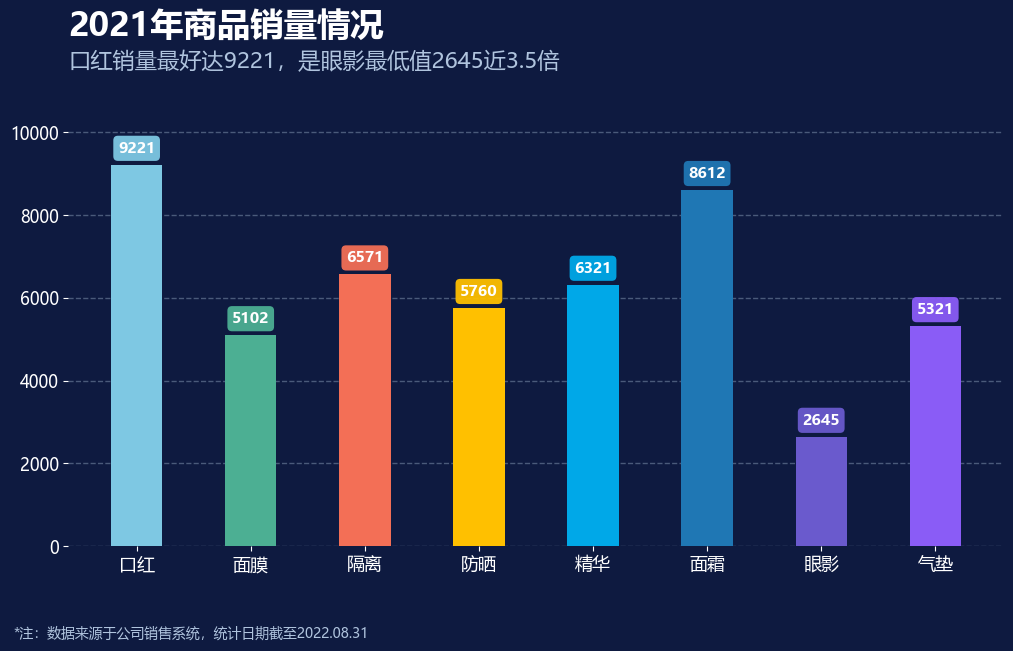

In [6]:
# ============================================================
# 图4：标注柱形图（多色彩版）
# ============================================================
items_4 = ['口红', '面膜', '隔离', '防晒', '精华', '面霜', '眼影', '气垫']
sales_4 = [9221, 5102, 6571, 5760, 6321, 8612, 2645, 5321]

# 为每个商品分配不同的颜色，参考目标图的视觉风格
colors_4 = [
    '#7EC8E3',  # 口红：浅蓝色
    '#4CAF93',  # 面膜：蓝绿色
    '#F36F56',  # 隔离：珊瑚红
    '#FFC000',  # 防晒：金黄色
    '#00A8E8',  # 精华：亮蓝色
    '#1F77B4',  # 面霜：深蓝色
    '#6A5ACD',  # 眼影：紫蓝色
    '#8A5CF6',  # 气垫：紫罗兰色
]

# 计算极值
max_item_4 = items_4[sales_4.index(max(sales_4))]
max_sales_4 = max(sales_4)
min_item_4 = items_4[sales_4.index(min(sales_4))]
min_sales_4 = min(sales_4)
ratio_4 = max_sales_4 / min_sales_4

fig4, ax4 = plt.subplots(figsize=(11, 7), facecolor='#0E1A40')
ax4.set_facecolor('#0E1A40')

# 绘制柱形图，指定多色
bars4 = ax4.bar(items_4, sales_4, color=colors_4, width=0.45, zorder=3)

# 添加数值标签（带与柱子同色的圆角背景框）
for i, (bar, color) in enumerate(zip(bars4, colors_4)):
    height = bar.get_height()
    ax4.text(
        bar.get_x() + bar.get_width() / 2, 
        height + 200, 
        f'{height}',
        ha='center', 
        va='bottom', 
        color='white', 
        fontsize=11, 
        fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.3", fc=color, ec="none", alpha=0.95),
        zorder=4
    )

# 设置标题和副标题
ax4.set_title('2021年商品销量情况', color='white', fontsize=24, fontweight='bold',
              pad=40, loc='left')
ax4.text(0, 1.04,
         f'{max_item_4}销量最好达{max_sales_4}，是{min_item_4}最低值{min_sales_4}近{ratio_4:.1f}倍',
         transform=ax4.transAxes, color='#B0C4DE', fontsize=16, ha='left', va='bottom')

# 设置 Y 轴范围和刻度
ax4.set_ylim(0, 11000)
ax4.set_yticks([0, 2000, 4000, 6000, 8000, 10000])
ax4.tick_params(axis='y', colors='white', labelsize=12)
ax4.tick_params(axis='x', colors='white', labelsize=13)

# 水平虚线网格
ax4.yaxis.grid(True, color='#4A5A7A', linestyle='--', linewidth=1, zorder=0)

# 隐藏边框
for spine in ax4.spines.values():
    spine.set_visible(False)

# 底部注释
fig4.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.08.31',
          color='#B0C4DE', fontsize=10)

# 调整布局并保存
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)
fig4.savefig('图4_标注柱形图.png', dpi=300,
             facecolor=fig4.get_facecolor(), bbox_inches='tight')
plt.show()
plt.close(fig4)


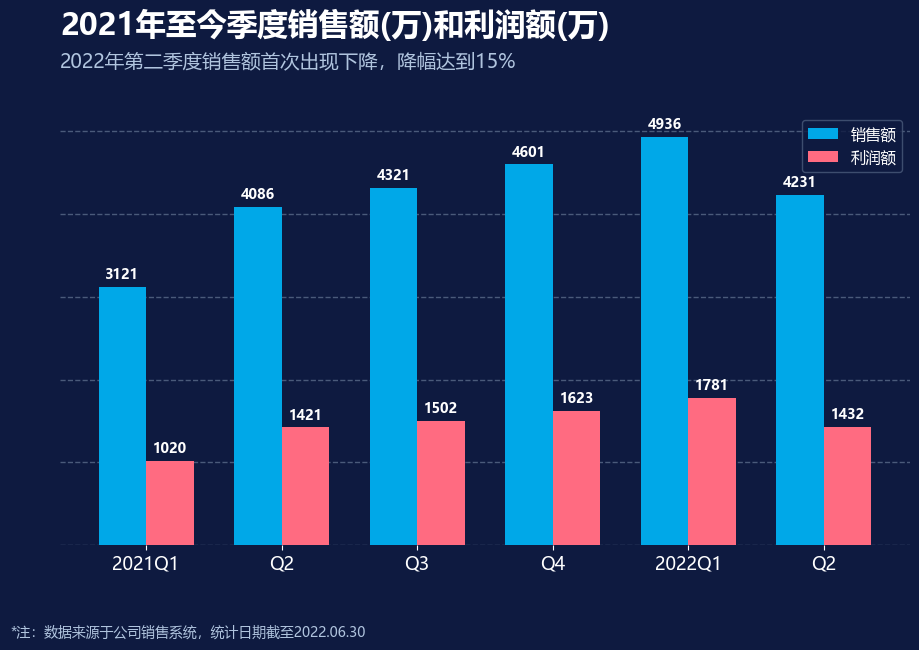

In [7]:
# ============================================================
# 图5：季度销售额与利润额对比图（并排柱形图）
# ============================================================
quarters_5 = ['2021Q1', 'Q2', 'Q3', 'Q4', '2022Q1', 'Q2']
sales_amount_5 = [3121, 4086, 4321, 4601, 4936, 4231]
profit_5 = [1020, 1421, 1502, 1623, 1781, 1432]

# 设置X轴位置和柱子宽度
x = np.arange(len(quarters_5))
width = 0.35

fig5, ax5 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax5.set_facecolor('#0E1A40')

# 并排绘制销售额和利润额
bars_sales = ax5.bar(x - width/2, sales_amount_5, width, 
                     label='销售额', color='#00A8E8', zorder=3)
bars_profit = ax5.bar(x + width/2, profit_5, width, 
                      label='利润额', color='#FF6B81', zorder=3)

# 添加柱顶数值标签
for i in range(len(quarters_5)):
    ax5.text(x[i] - width/2, sales_amount_5[i] + 50, f'{sales_amount_5[i]}',
             ha='center', va='bottom', color='white', fontsize=10, fontweight='bold')
    ax5.text(x[i] + width/2, profit_5[i] + 50, f'{profit_5[i]}',
             ha='center', va='bottom', color='white', fontsize=10, fontweight='bold')

# 设置标题和副标题
ax5.set_title('2021年至今季度销售额(万)和利润额(万)', 
              color='white', fontsize=22, fontweight='bold', pad=40, loc='left')
ax5.text(0, 1.04,
         '2022年第二季度销售额首次出现下降，降幅达到15%',
         transform=ax5.transAxes, color='#B0C4DE', fontsize=14,
         ha='left', va='bottom')

# 设置X轴刻度和标签
ax5.set_xticks(x)
ax5.set_xticklabels(quarters_5)
ax5.tick_params(axis='x', colors='white', labelsize=13)

# Y轴设置：隐藏刻度数字，只保留网格线
ax5.set_ylim(0, 5500)
ax5.set_yticks([0, 1000, 2000, 3000, 4000, 5000])
ax5.set_yticklabels([])  # 隐藏Y轴数字
ax5.tick_params(axis='y', length=0)  # 隐藏Y轴刻度线

# 水平虚线网格
ax5.yaxis.grid(True, color='#4A5A7A', linestyle='--', linewidth=1, zorder=0)

# 隐藏边框
for spine in ax5.spines.values():
    spine.set_visible(False)

# 图例（右上角，带边框）
legend5 = ax5.legend(loc='upper right', bbox_to_anchor=(1, 0.95),
                     facecolor='#0E1A40', edgecolor='#4A5A7A', fontsize=11)
for text in legend5.get_texts():
    text.set_color('white')

# 底部注释
fig5.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
          color='#B0C4DE', fontsize=10)

# 调整布局并保存
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)
fig5.savefig('图5_层叠柱形图.png', dpi=300,
             facecolor=fig5.get_facecolor(), bbox_inches='tight')
plt.show()


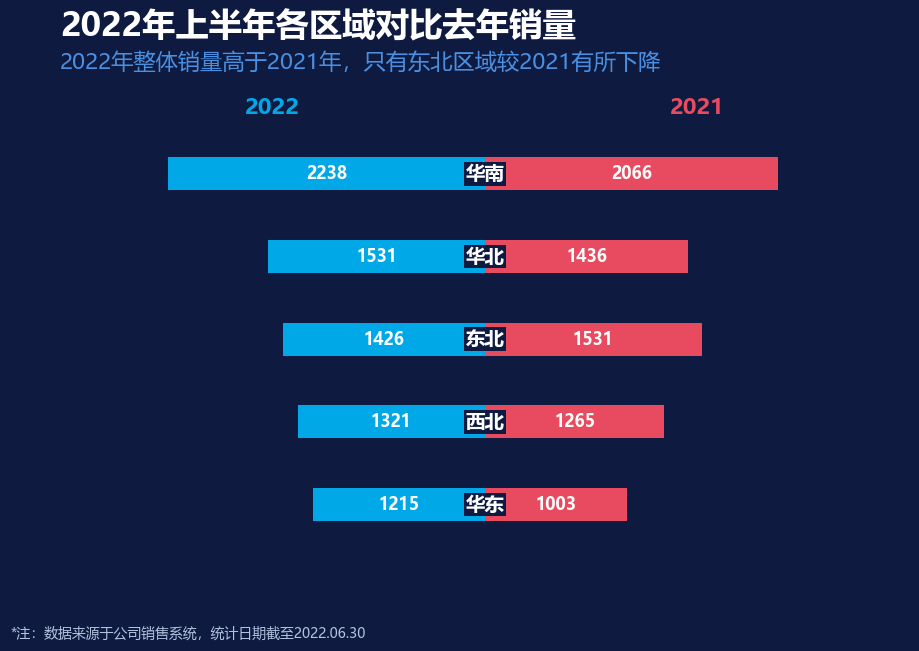

In [8]:
# ============================================================
# 图6：蝴蝶图（对比柱形图）
# ============================================================
# 数据准备
regions = ['华南', '华北', '东北', '西北', '华东']
sales_2022 = [2238, 1531, 1426, 1321, 1215]
sales_2021 = [2066, 1436, 1531, 1265, 1003]

# 创建画布
fig6, ax6 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax6.set_facecolor('#0E1A40')

# y轴位置和条形宽度
y_pos = np.arange(len(regions))
bar_height = 0.4

# 绘制左侧（2022年）条形，使用负值实现向左延伸
ax6.barh(y_pos, [-x for x in sales_2022], height=bar_height, 
         color='#00A8E8', zorder=3)

# 绘制右侧（2021年）条形，使用正值实现向右延伸
ax6.barh(y_pos, sales_2021, height=bar_height, 
         color='#E84A5F', zorder=3)

# 添加数值标签（条形图内部居中）
for i in range(len(regions)):
    # 2022年数值标签
    ax6.text(-sales_2022[i] / 2, i, str(sales_2022[i]), 
             ha='center', va='center', color='white', 
             fontsize=12, fontweight='bold', zorder=4)
    # 2021年数值标签
    ax6.text(sales_2021[i] / 2, i, str(sales_2021[i]), 
             ha='center', va='center', color='white', 
             fontsize=12, fontweight='bold', zorder=4)

# 添加中间区域标签
for i, region in enumerate(regions):
    ax6.text(0, i, region, ha='center', va='center', color='white', 
             fontsize=14, fontweight='bold', zorder=5,
             bbox=dict(facecolor='#0E1A40', edgecolor='none', pad=1))

# 添加顶部年份标签
ax6.text(-1500, -0.8, '2022', ha='center', va='center', 
         color='#00A8E8', fontsize=16, fontweight='bold')
ax6.text(1500, -0.8, '2021', ha='center', va='center', 
         color='#E84A5F', fontsize=16, fontweight='bold')

# 添加标题和副标题
ax6.set_title('2022年上半年各区域对比去年销量', color='white', 
              fontsize=24, fontweight='bold', pad=40, loc='left')
ax6.text(0, 1.04, '2022年整体销量高于2021年，只有东北区域较2021有所下降', 
         transform=ax6.transAxes, color='#4A90E2', fontsize=16, 
         ha='left', va='bottom')

# 隐藏坐标轴刻度和边框
ax6.set_xticks([])
ax6.set_yticks([])
for spine in ax6.spines.values():
    spine.set_visible(False)

# 设置x轴和y轴范围
ax6.set_xlim(-3000, 3000)
ax6.set_ylim(len(regions) - 0.5, -1)  # 反转y轴，使第一项在最上方

# 添加底部注释
fig6.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
          color='#B0C4DE', fontsize=10)

# 调整布局
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)

# 显示图片（在 Jupyter 中直接显示）
plt.show()

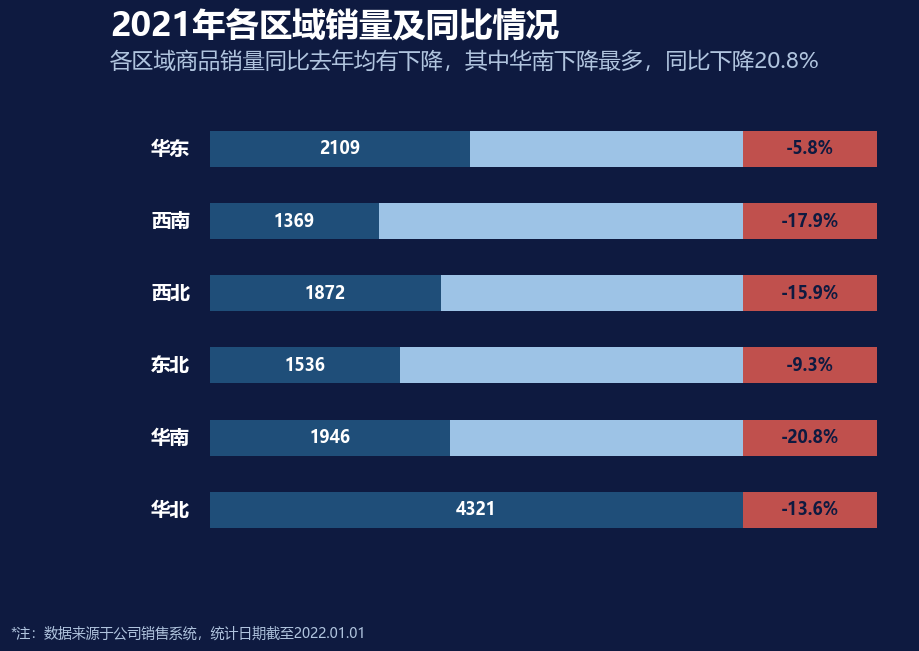

In [9]:
# ============================================================
# 图8：销量及同比情况（水平堆积条形图）
# ============================================================
# 数据准备（来源于Excel工作表8，按图片顺序从上到下排列）
regions = ['华东', '西南', '西北', '东北', '华南', '华北']
sales = [2109, 1369, 1872, 1536, 1946, 4321]
yoy = [-0.058, -0.179, -0.159, -0.093, -0.208, -0.136]

max_sales = max(sales)

# 计算各段宽度
# 左侧蓝色区域总宽度设定为 8，右侧红色区域固定宽度设定为 2
blue_total_width = 8
red_width = 2

# 深蓝色段 = (当前销量 / 最大销量) * 蓝色总宽度
w_dark = [(s / max_sales) * blue_total_width for s in sales]
# 浅蓝色段 = 蓝色总宽度 - 深蓝色段
w_light = [blue_total_width - d for d in w_dark]

# 创建画布
fig8, ax8 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax8.set_facecolor('#0E1A40')

y_pos = np.arange(len(regions))
bar_height = 0.5

# 绘制深蓝色段（销量）
ax8.barh(y_pos, w_dark, height=bar_height, color='#1F4E79', zorder=3)

# 绘制浅蓝色段（占位，实现右侧对齐）
ax8.barh(y_pos, w_light, left=w_dark, height=bar_height, color='#9DC3E6', zorder=3)

# 绘制红色段（同比百分比，固定宽度）
ax8.barh(y_pos, red_width, left=blue_total_width, height=bar_height, color='#C0504D', zorder=3)

# 添加数值标签（居中显示在深蓝色条形内部）
for i in range(len(regions)):
    ax8.text(w_dark[i] / 2, i, str(sales[i]), 
             ha='center', va='center', color='white', 
             fontsize=12, fontweight='bold', zorder=4)

# 添加同比百分比标签（居中显示在红色条形内部）
for i in range(len(regions)):
    ax8.text(blue_total_width + red_width / 2, i, f'{yoy[i]*100:.1f}%', 
             ha='center', va='center', color='#0E1A40', 
             fontsize=12, fontweight='bold', zorder=4)

# 添加左侧区域标签
for i, region in enumerate(regions):
    ax8.text(-0.3, i, region, ha='right', va='center', color='white', 
             fontsize=14, fontweight='bold', zorder=5)

# 隐藏坐标轴刻度和边框
ax8.set_xticks([])
ax8.set_yticks([])
for spine in ax8.spines.values():
    spine.set_visible(False)

# 设置x轴和y轴范围
ax8.set_xlim(-1.5, blue_total_width + red_width + 0.5)
ax8.set_ylim(len(regions) - 0.5, -0.8)  # 反转y轴，使第一项在最上方

# 添加标题和副标题
ax8.set_title('2021年各区域销量及同比情况', color='white', 
              fontsize=24, fontweight='bold', pad=40, loc='left')
ax8.text(0, 1.04, '各区域商品销量同比去年均有下降，其中华南下降最多，同比下降20.8%', 
         transform=ax8.transAxes, color='#B0C4DE', fontsize=16, 
         ha='left', va='bottom')

# 添加底部注释
fig8.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.01.01',
          color='#B0C4DE', fontsize=10)

# 调整布局
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.15, right=0.95)

# 显示图片（在 Jupyter 中直接显示）
plt.show()

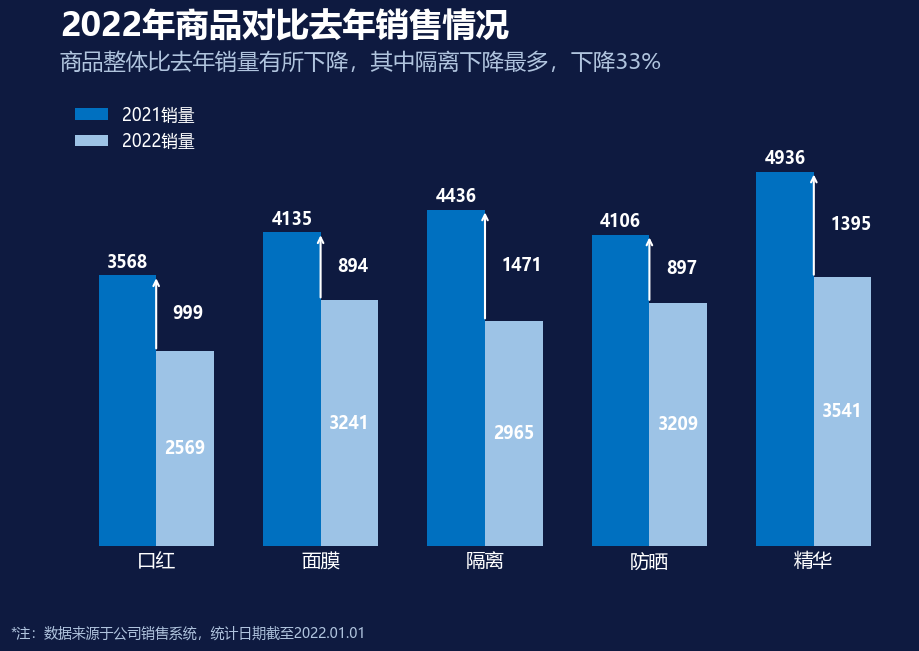

In [13]:
# ============================================================
# 图9：对比柱形图（2021 vs 2022 销量对比）
# ============================================================
# 数据准备
products = ['口红', '面膜', '隔离', '防晒', '精华']
sales_2021 = [3568, 4135, 4436, 4106, 4936]
sales_2022 = [2569, 3241, 2965, 3209, 3541]
diff = [sales_2021[i] - sales_2022[i] for i in range(len(products))]

# 创建画布
fig9, ax9 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax9.set_facecolor('#0E1A40')

# x轴位置与条形宽度
x = np.arange(len(products))
width = 0.35

# 绘制 2021年 深蓝色柱形
ax9.bar(x - width/2, sales_2021, width, label='2021销量', 
        color='#0070C0', zorder=3)
# 绘制 2022年 浅蓝色柱形
ax9.bar(x + width/2, sales_2022, width, label='2022销量', 
        color='#9DC3E6', zorder=3)

# 添加 2021年 数值标签（柱形上方）
for i in range(len(products)):
    ax9.text(x[i] - width/2, sales_2021[i] + 50, str(sales_2021[i]), 
             ha='center', va='bottom', color='white', 
             fontsize=12, fontweight='bold', zorder=4)

# 添加 2022年 数值标签（柱形内部居中）
for i in range(len(products)):
    ax9.text(x[i] + width/2, sales_2022[i] / 2, str(sales_2022[i]), 
             ha='center', va='center', color='white', 
             fontsize=12, fontweight='bold', zorder=4)

# 添加竖直的差值箭头和文字
for i in range(len(products)):
    # 箭头水平位置固定在两根柱子中间
    arrow_x = x[i]
    
    # 起点：矮柱（2022年）的顶部
    start_y = sales_2022[i]
    # 终点：高柱（2021年）的顶部
    end_y = sales_2021[i]
    
    # 绘制竖直向上的箭头
    ax9.annotate('', xy=(arrow_x, end_y), xytext=(arrow_x, start_y),
                 arrowprops=dict(arrowstyle='->', color='white', 
                                 linewidth=1.5),
                 zorder=5)
    
    # 差值文字放在箭头的右侧，垂直居中
    ax9.text(arrow_x + 0.1, (start_y + end_y) / 2, str(diff[i]), 
             ha='left', va='center', color='white', 
             fontsize=12, fontweight='bold', zorder=6)

# 添加标题和副标题
ax9.set_title('2022年商品对比去年销售情况', color='white', 
              fontsize=24, fontweight='bold', pad=40, loc='left')
ax9.text(0, 1.04, '商品整体比去年销量有所下降，其中隔离下降最多，下降33%', 
         transform=ax9.transAxes, color='#B0C4DE', fontsize=16, 
         ha='left', va='bottom')

# 设置x轴刻度
ax9.set_xticks(x)
ax9.set_xticklabels(products, color='white', fontsize=14)
ax9.tick_params(axis='x', length=0)

# 隐藏y轴刻度和边框
ax9.set_yticks([])
for spine in ax9.spines.values():
    spine.set_visible(False)

# 设置y轴范围
ax9.set_ylim(0, 6000)

# 图例样式
legend = ax9.legend(loc='upper left', facecolor='#0E1A40', 
                    edgecolor='none', fontsize=12, framealpha=0)
for text in legend.get_texts():
    text.set_color('white')

# 添加底部注释
fig9.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.01.01',
          color='#B0C4DE', fontsize=10)

# 调整布局
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)

# 显示图片
plt.show()

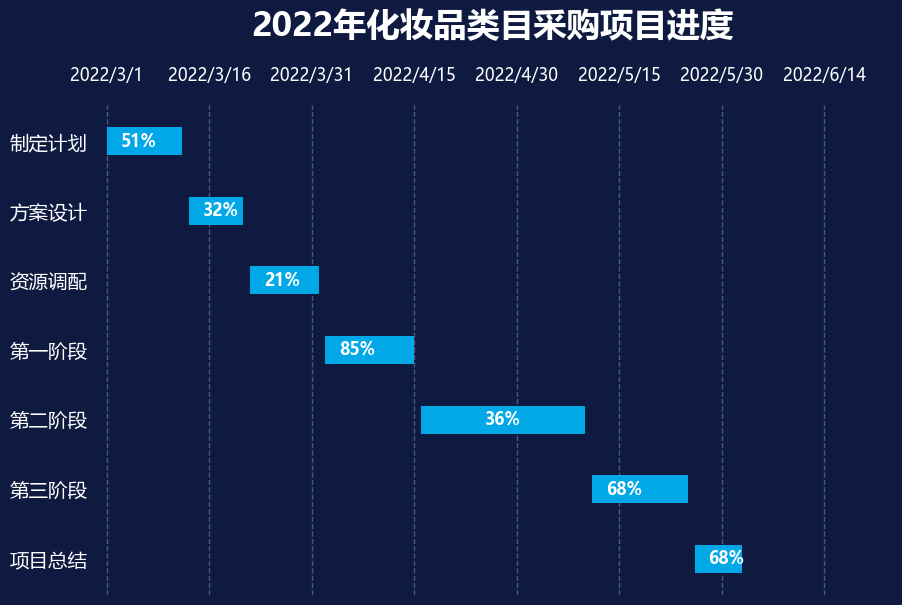

In [15]:
from datetime import datetime
# ============================================================
# 图10：甘特图（项目进度）
# ============================================================
# 数据准备（来源于Excel工作表10）
projects = ['制定计划', '方案设计', '资源调配', '第一阶段', '第二阶段', '第三阶段', '项目总结']
start_dates_str = ['2022-03-01', '2022-03-13', '2022-03-22', '2022-04-02', 
                   '2022-04-16', '2022-05-11', '2022-05-26']
durations = [11, 8, 10, 13, 24, 14, 7]
progress = [0.51, 0.32, 0.21, 0.85, 0.36, 0.68, 0.68]

# 计算每个项目的开始天数（相对于 2022-03-01）
base_date = datetime(2022, 3, 1)
start_days = [(datetime.strptime(d, '%Y-%m-%d') - base_date).days for d in start_dates_str]

# 创建画布
fig10, ax10 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax10.set_facecolor('#0E1A40')

# Y轴位置
y_pos = np.arange(len(projects))
bar_height = 0.4

# 绘制水平条形图（甘特图）
# left=start_days 表示从第几天开始，width=durations 表示持续天数
bars = ax10.barh(y_pos, durations, left=start_days, height=bar_height, 
                 color='#00A8E8', zorder=3)

# 添加百分比文字标签
for i in range(len(projects)):
    # 根据条形长度决定文字位置
    if durations[i] > 15:
        # 长条形文字居中
        text_x = start_days[i] + durations[i] / 2
        ha = 'center'
    else:
        # 短条形文字靠左
        text_x = start_days[i] + 2
        ha = 'left'
    
    ax10.text(text_x, i, f'{progress[i]*100:.0f}%', 
              ha=ha, va='center', color='white', 
              fontsize=12, fontweight='bold', zorder=4)

# 设置Y轴标签（项目名称）
ax10.set_yticks(y_pos)
ax10.set_yticklabels(projects, color='white', fontsize=14)
ax10.tick_params(axis='y', length=0)  # 隐藏Y轴刻度线
ax10.invert_yaxis()  # 反转Y轴，使第一个项目在最上方

# 设置顶部X轴刻度和日期标签
xticks_days = [0, 15, 30, 45, 60, 75, 90, 105]
xtick_labels = ['2022/3/1', '2022/3/16', '2022/3/31', '2022/4/15', 
                '2022/4/30', '2022/5/15', '2022/5/30', '2022/6/14']
ax10.set_xticks(xticks_days)
ax10.set_xticklabels(xtick_labels, color='white', fontsize=12)
ax10.xaxis.tick_top()  # 将X轴刻度移至顶部
ax10.xaxis.set_label_position('top')
ax10.tick_params(axis='x', length=0, pad=15)  # 隐藏刻度线，增加标签与轴的距离

# 添加垂直虚线网格
for day in xticks_days:
    ax10.axvline(x=day, color='#4A5A7A', linestyle='--', linewidth=1, zorder=1)

# 添加标题
ax10.set_title('2022年化妆品类目采购项目进度', color='white', 
               fontsize=24, fontweight='bold', pad=50, loc='center')

# 隐藏边框
for spine in ax10.spines.values():
    spine.set_visible(False)

# 设置X轴范围
ax10.set_xlim(-2, 115)

# 调整布局
plt.subplots_adjust(top=0.8, bottom=0.1, left=0.15, right=0.95)

# 显示图片（在 Jupyter 中直接显示）
plt.show()

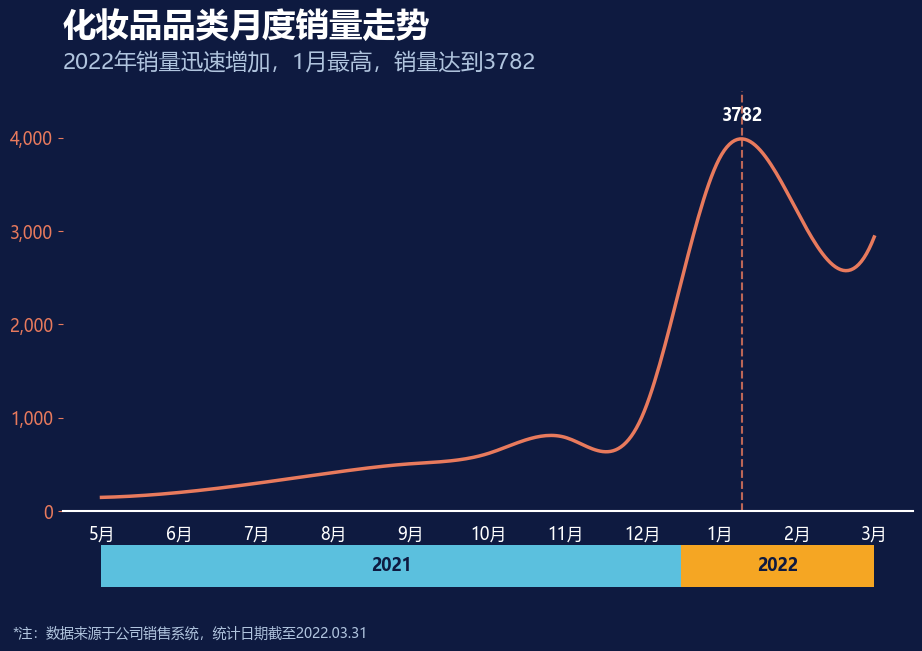

In [18]:
from scipy.interpolate import make_interp_spline
from matplotlib.patches import Rectangle
# ============================================================
# 图11：平滑折线图（化妆品品类月度销量走势）
# ============================================================
# 数据准备（来源于Excel工作表11）
months = ['5月', '6月', '7月', '8月', '9月', '10月', '11月', '12月', '1月', '2月', '3月']
sales = [146, 198, 296, 412, 506, 615, 789, 1021, 3782, 3215, 2936]

# 生成平滑曲线数据
x = np.arange(len(months))
x_smooth = np.linspace(0, len(months) - 1, 300)
y_smooth = make_interp_spline(x, sales, k=3)(x_smooth)

# 获取平滑曲线实际最高点的坐标
peak_smooth_idx = np.argmax(y_smooth)
peak_x = x_smooth[peak_smooth_idx]
peak_y = y_smooth[peak_smooth_idx]

# 创建画布
fig11, ax11 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax11.set_facecolor('#0E1A40')

# 绘制平滑折线
line_color = '#E87A5D'  # 橙色/珊瑚色
ax11.plot(x_smooth, y_smooth, color=line_color, linewidth=2.5, zorder=3)

# 添加最高点处的垂直虚线（使用平滑曲线的实际最高点坐标）
ax11.axvline(x=peak_x, color=line_color, linestyle='--', linewidth=1.5, alpha=0.8, zorder=2)

# 添加峰值数值标签（使用实际峰值坐标，确保对正）
ax11.text(peak_x, peak_y + 150, str(sales[8]), 
          ha='center', va='bottom', color='white', fontsize=12, fontweight='bold', zorder=4)

# 设置Y轴刻度和样式
ax11.set_ylim(0, 4500)
ax11.set_yticks([0, 1000, 2000, 3000, 4000])
ax11.set_yticklabels(['0', '1,000', '2,000', '3,000', '4,000'])
ax11.tick_params(axis='y', colors=line_color, labelsize=12)

# 设置X轴刻度和样式
ax11.set_xticks(x)
ax11.set_xticklabels(months, color='white', fontsize=12)
ax11.tick_params(axis='x', length=0, pad=10)

# 隐藏顶部、右侧、左侧边框，保留底部边框
ax11.spines['top'].set_visible(False)
ax11.spines['right'].set_visible(False)
ax11.spines['left'].set_visible(False)
ax11.spines['bottom'].set_color('white')
ax11.spines['bottom'].set_linewidth(1.5)

# 设置X轴范围
ax11.set_xlim(-0.5, len(months) - 0.5)

# 添加底部 2021 / 2022 彩色区间标签
rect_2021 = Rectangle((0, -0.18), 7.5, 0.1, transform=ax11.get_xaxis_transform(),
                      facecolor='#5BC0DE', edgecolor='none', clip_on=False, zorder=5)
rect_2022 = Rectangle((7.5, -0.18), 2.5, 0.1, transform=ax11.get_xaxis_transform(),
                      facecolor='#F5A623', edgecolor='none', clip_on=False, zorder=5)
ax11.add_patch(rect_2021)
ax11.add_patch(rect_2022)

# 添加区间文字
ax11.text(3.75, -0.13, '2021', transform=ax11.get_xaxis_transform(),
          ha='center', va='center', color='#0E1A40', fontsize=12, fontweight='bold', zorder=6)
ax11.text(8.75, -0.13, '2022', transform=ax11.get_xaxis_transform(),
          ha='center', va='center', color='#0E1A40', fontsize=12, fontweight='bold', zorder=6)

# 添加标题和副标题
ax11.set_title('化妆品品类月度销量走势', color='white', 
               fontsize=24, fontweight='bold', pad=40, loc='left')
ax11.text(0, 1.04, '2022年销量迅速增加，1月最高，销量达到3782', 
          transform=ax11.transAxes, color='#B0C4DE', fontsize=16, 
          ha='left', va='bottom')

# 添加底部注释
fig11.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.03.31',
           color='#B0C4DE', fontsize=10)

# 调整布局
plt.subplots_adjust(top=0.8, bottom=0.2, left=0.1, right=0.95)

# 显示图片（在 Jupyter 中直接显示）
plt.show()

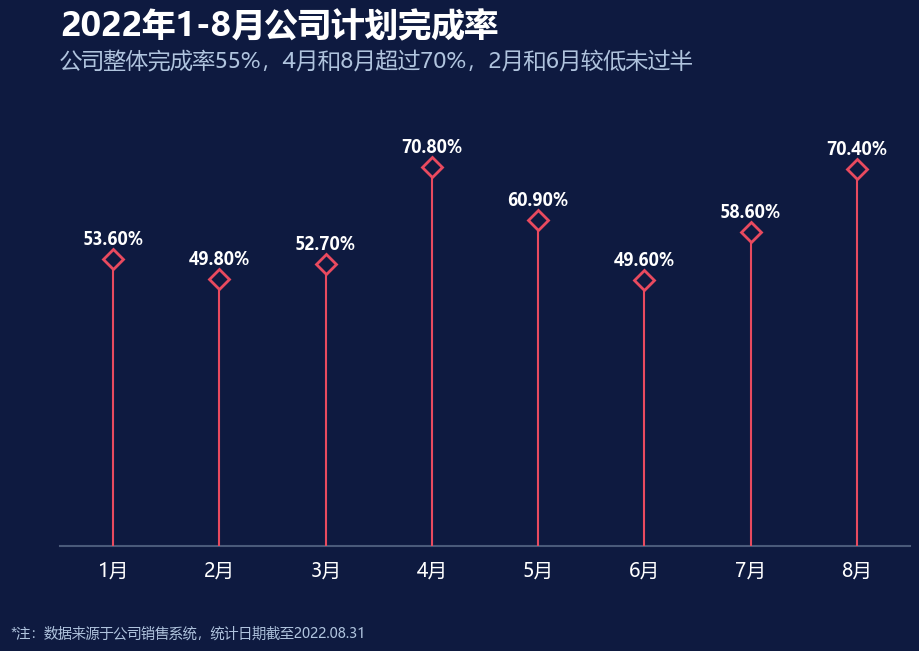

In [19]:
# ============================================================
# 图12：菱形走势图（计划完成率）
# ============================================================
# 数据准备（来源于Excel工作表12）
months = ['1月', '2月', '3月', '4月', '5月', '6月', '7月', '8月']
rates = [0.536, 0.498, 0.527, 0.708, 0.609, 0.496, 0.586, 0.704]

# 创建画布
fig12, ax12 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax12.set_facecolor('#0E1A40')

# X轴位置
x = np.arange(len(months))

# 线条和标记颜色
line_color = '#E84A5F'  # 红色/珊瑚色

# 1. 绘制垂直直线（从 0 到 rates 高度）
ax12.vlines(x, 0, rates, color=line_color, linewidth=1.5, zorder=3)

# 2. 绘制顶部的菱形标记（空心效果，深色填充，红色描边）
ax12.plot(x, rates, 'D', color='#0E1A40', markeredgecolor=line_color, 
          markeredgewidth=2, markersize=10, zorder=4)

# 3. 添加百分比数值标签
for i in range(len(months)):
    ax12.text(x[i], rates[i] + 0.02, f'{rates[i]*100:.2f}%', 
              ha='center', va='bottom', color='white', 
              fontsize=12, fontweight='bold', zorder=5)

# 设置X轴刻度和样式
ax12.set_xticks(x)
ax12.set_xticklabels(months, color='white', fontsize=14)
ax12.tick_params(axis='x', length=0, pad=10)

# 隐藏Y轴刻度和边框
ax12.set_yticks([])
ax12.spines['top'].set_visible(False)
ax12.spines['right'].set_visible(False)
ax12.spines['left'].set_visible(False)
ax12.spines['bottom'].set_color('#4A5A7A')  # 底部保留一根浅色轴线
ax12.spines['bottom'].set_linewidth(1.5)

# 设置Y轴范围（给顶部标签留出空间）
ax12.set_ylim(0, 0.85)
ax12.set_xlim(-0.5, len(months) - 0.5)

# 添加标题和副标题
ax12.set_title('2022年1-8月公司计划完成率', color='white', 
               fontsize=24, fontweight='bold', pad=40, loc='left')
ax12.text(0, 1.04, '公司整体完成率55%，4月和8月超过70%，2月和6月较低未过半', 
          transform=ax12.transAxes, color='#B0C4DE', fontsize=16, 
          ha='left', va='bottom')

# 添加底部注释
fig12.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.08.31',
           color='#B0C4DE', fontsize=10)

# 调整布局
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)

# 显示图片（在 Jupyter 中直接显示）
plt.show()

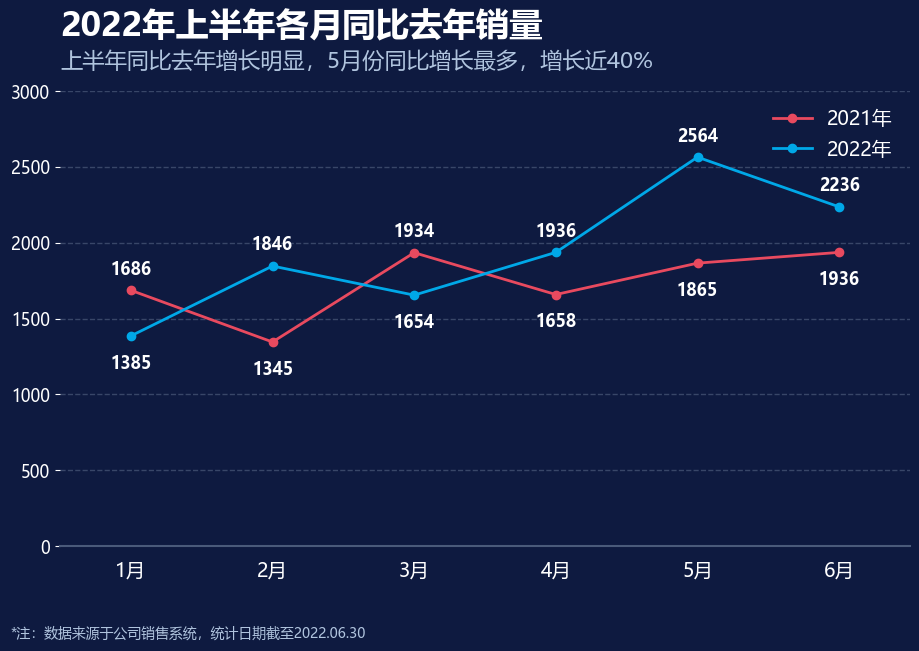

In [20]:
# ============================================================
# 图13：对比折线图（2022年上半年各月同比去年销量）
# ============================================================
# 数据准备（来源于Excel工作表13）
months = ['1月', '2月', '3月', '4月', '5月', '6月']
sales_2021 = [1686, 1345, 1934, 1658, 1865, 1936]
sales_2022 = [1385, 1846, 1654, 1936, 2564, 2236]

# 创建画布
fig13, ax13 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax13.set_facecolor('#0E1A40')

# X轴位置
x = np.arange(len(months))

# 绘制折线（带圆点标记）
ax13.plot(x, sales_2021, marker='o', color='#E84A5F', label='2021年', 
          linewidth=2, markersize=6, zorder=3)
ax13.plot(x, sales_2022, marker='o', color='#00A8E8', label='2022年', 
          linewidth=2, markersize=6, zorder=3)

# 添加数据标签
for i in range(len(months)):
    # 判断2021和2022数据的高低，决定标签放在上方还是下方，避免重叠
    if sales_2021[i] > sales_2022[i]:
        # 2021年数据高，标签在上方；2022年数据低，标签在下方
        ax13.text(x[i], sales_2021[i] + 80, str(sales_2021[i]), 
                  ha='center', va='bottom', color='white', fontsize=12, fontweight='bold')
        ax13.text(x[i], sales_2022[i] - 120, str(sales_2022[i]), 
                  ha='center', va='top', color='white', fontsize=12, fontweight='bold')
    else:
        # 2022年数据高，标签在上方；2021年数据低，标签在下方
        ax13.text(x[i], sales_2022[i] + 80, str(sales_2022[i]), 
                  ha='center', va='bottom', color='white', fontsize=12, fontweight='bold')
        ax13.text(x[i], sales_2021[i] - 120, str(sales_2021[i]), 
                  ha='center', va='top', color='white', fontsize=12, fontweight='bold')

# 设置Y轴刻度和样式
ax13.set_ylim(0, 3000)
ax13.set_yticks([0, 500, 1000, 1500, 2000, 2500, 3000])
ax13.set_yticklabels(['0', '500', '1000', '1500', '2000', '2500', '3000'])
ax13.tick_params(axis='y', colors='white', labelsize=12)

# 添加水平虚线网格
ax13.yaxis.grid(True, color='#4A5A7A', linestyle='--', linewidth=1, alpha=0.7, zorder=0)

# 设置X轴刻度和样式
ax13.set_xticks(x)
ax13.set_xticklabels(months, color='white', fontsize=14)
ax13.tick_params(axis='x', length=0, pad=10)

# 隐藏顶部、右侧、左侧边框，保留底部边框
ax13.spines['top'].set_visible(False)
ax13.spines['right'].set_visible(False)
ax13.spines['left'].set_visible(False)
ax13.spines['bottom'].set_color('#4A5A7A')
ax13.spines['bottom'].set_linewidth(1.5)

# 设置X轴范围
ax13.set_xlim(-0.5, len(months) - 0.5)

# 添加图例（右上角，无背景框，文字白色）
legend = ax13.legend(loc='upper right', facecolor='#0E1A40', 
                     edgecolor='none', fontsize=14, framealpha=0)
for text in legend.get_texts():
    text.set_color('white')

# 添加标题和副标题
ax13.set_title('2022年上半年各月同比去年销量', color='white', 
               fontsize=24, fontweight='bold', pad=40, loc='left')
ax13.text(0, 1.04, '上半年同比去年增长明显，5月份同比增长最多，增长近40%', 
          transform=ax13.transAxes, color='#B0C4DE', fontsize=16, 
          ha='left', va='bottom')

# 添加底部注释
fig13.text(0.05, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
           color='#B0C4DE', fontsize=10)

# 调整布局
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)

# 显示图片（在 Jupyter 中直接显示）
plt.show()

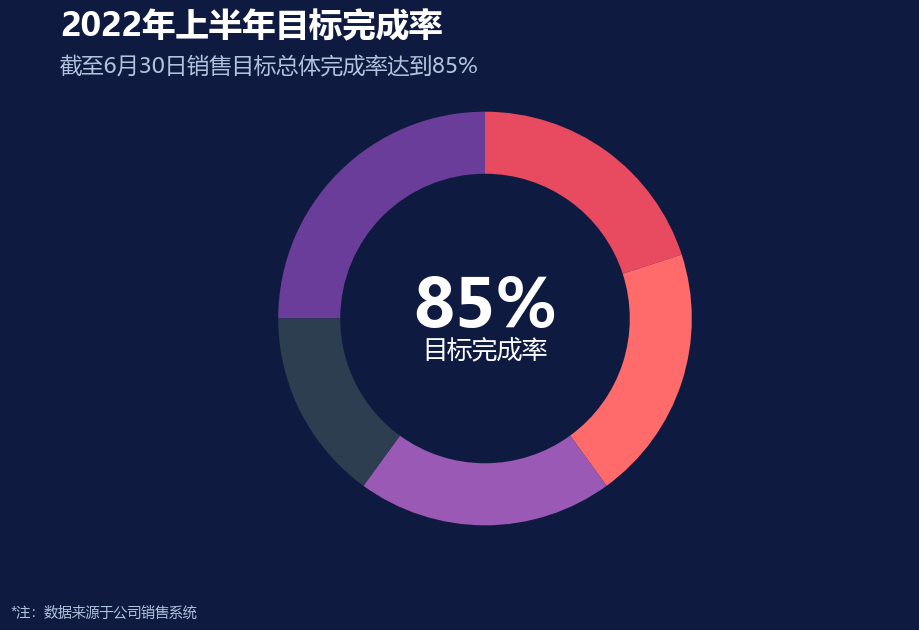

In [23]:
# ============================================================
# 图14：单值圆环图（目标完成率）
# ============================================================
# 创建画布
fig14, ax14 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax14.set_facecolor('#0E1A40')

# 数据准备：将 85% 的进度拆分为多段以模拟渐变效果
# 25% + 20% + 20% + 20% = 85%
sizes = [25, 20, 20, 20, 15]
# 从深紫 -> 粉红 -> 珊瑚 -> 紫色 -> 灰色（底环）
colors = ['#6A3D9A', '#E84A5F', '#FF6B6B', '#9B59B6', '#2C3E50']

# 绘制环形图
# startangle=180 表示从左侧（9点钟方向）开始
# counterclock=False 表示顺时针绘制
wedges, texts = ax14.pie(sizes, startangle=180, counterclock=False,
                         colors=colors, 
                         wedgeprops=dict(width=0.3, edgecolor='none'))

# 添加中心文字：85%
ax14.text(0, 0.05, '85%', ha='center', va='center', 
          color='white', fontsize=48, fontweight='bold', zorder=5)

# 添加中心文字：目标完成率
ax14.text(0, -0.15, '目标完成率', ha='center', va='center', 
          color='white', fontsize=18, zorder=5)

# 确保环形为正圆
ax14.axis('equal')

# 添加标题和副标题
ax14.set_title('2022年上半年目标完成率', color='white', 
               fontsize=24, fontweight='bold', pad=40, loc='left')

# 使用 fig.text 放置副标题，以确保位置精准
fig14.text(0.1, 0.82, '截至6月30日销售目标总体完成率达到85%', 
           color='#B0C4DE', fontsize=16, ha='left', va='bottom')

# 添加底部注释
fig14.text(0.05, 0.05, '*注：数据来源于公司销售系统',
           color='#B0C4DE', fontsize=10)

# 调整布局边距
plt.subplots_adjust(top=0.8, bottom=0.15, left=0.1, right=0.95)

# 显示图片（在 Jupyter 中直接显示）
plt.show()

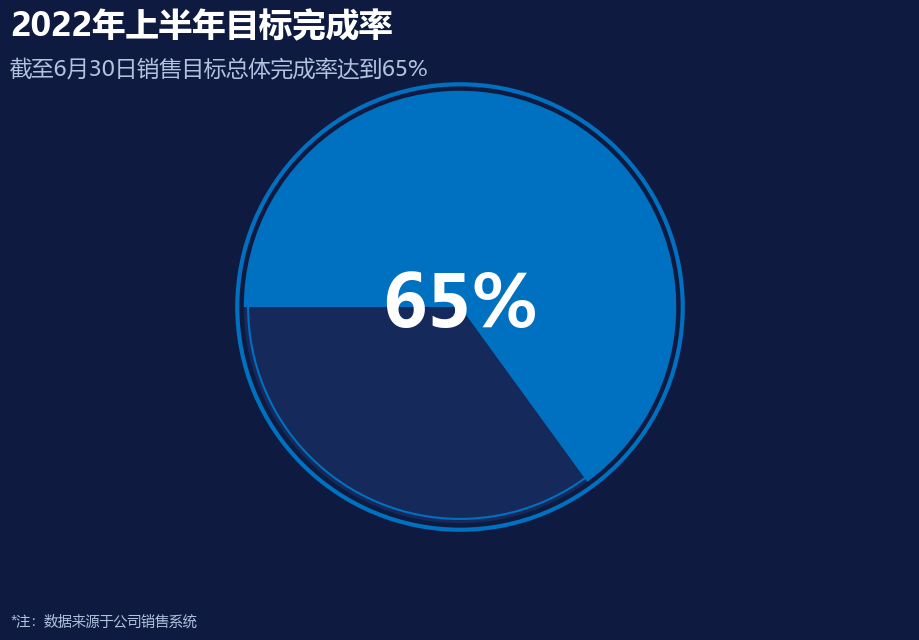

In [2]:
# ============================================================
# 图15：水球图（目标完成率 65%）
# ============================================================

# 创建画布
fig15, ax15 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax15.set_facecolor('#0E1A40')

# 数据准备：来自 Sheet 15 的数据，完成率 0.65，辅助 1（占比 0.35）
sizes = [0.65, 0.35]

# 颜色配置：亮蓝色表示完成进度，深蓝色背景表示未完成部分
colors = ['#0070C0', '#152A5A']  # 亮蓝 / 深蓝

# 绘制水球图（实心圆，width=1 表示从圆心到边缘完全填充）
# startangle=180 表示从左侧（9点钟方向）开始，counterclock=False 表示顺时针绘制
wedges, texts = ax15.pie(sizes, startangle=180, counterclock=False,
                         colors=colors, 
                         wedgeprops=dict(width=1.0, edgecolor='none'))

# 添加外轮廓线（参考图片，有内外两层圆圈边框）
# 外圈
circle_outer = plt.Circle((0, 0), 1.03, color='#0070C0', fill=False, linewidth=3, zorder=10)
ax15.add_patch(circle_outer)
# 内圈
circle_inner = plt.Circle((0, 0), 0.98, color='#0070C0', fill=False, linewidth=1.5, zorder=10)
ax15.add_patch(circle_inner)

# 添加中心文字：65%
ax15.text(0, 0, '65%', ha='center', va='center', 
          color='white', fontsize=52, fontweight='bold', zorder=11)

# 确保图形为正圆
ax15.axis('equal')

# 隐藏坐标轴边框
ax15.axis('off')

# 添加标题和副标题（使用 fig.text 以确保在隐藏坐标轴后依然精确定位）
fig15.text(0.05, 0.9, '2022年上半年目标完成率', color='white', 
           fontsize=24, fontweight='bold', ha='left', va='center')

# 副标题
fig15.text(0.05, 0.84, '截至6月30日销售目标总体完成率达到65%', 
           color='#B0C4DE', fontsize=16, ha='left', va='center')
# 添加底部注释
fig15.text(0.05, 0.05, '*注：数据来源于公司销售系统',
           color='#B0C4DE', fontsize=10, ha='left', va='center')
# 调整布局边距
plt.subplots_adjust(top=0.85, bottom=0.15, left=0.05, right=0.95)
# 显示图片
plt.show()